# SmokeCheck: should practice move indoors tomorrow?

**Veritas AI International High School Hackathon 2026 · Track: AI + Climate**
(built on suggested project 4.3.2, next-day air quality forecast)

**One-sentence pitch:** SmokeCheck helps a Midwest high-school athletic director who has to plan tomorrow's
practice by taking today's air-quality readings and tomorrow's weather forecast, and telling them whether to
expect unhealthy smoke (a daily average above 35 µg/m³ of PM2.5).

**How to run:** Runtime → Run all. It needs no API keys or uploads, and finishes in under a minute.

## 1. Load the data

Three small files, all built by the scripts in this repo (`fetch_data.py`, `fetch_smoke.py`, `fetch_dayahead.py`):

- `data/daily.csv`, one row per city per day for six Midwest metro areas:
  - `obs_pm25`: what EPA monitors **measured**, averaged over the metro area (µg/m³). This is what we forecast.
  - `cams_pm25`: what the CAMS global air-quality **model** says (via Open-Meteo). An estimate on a 45 km grid, not a measurement.
  - weather from Open-Meteo: temperature, humidity, rain, wind speed and wind direction (`wind_u`, `wind_v`).
- `data/smoke_days.csv`: whether NOAA analysts drew a wildfire-smoke plume over the city on satellite images
  (`smoke`: 0 none, 1 light, 2 medium, 3 heavy).
- `data/weather_dayahead_2025.csv`: for 2025 only, the weather that was **forecast one day ahead**.
  Section 7 explains why we need it.
- `data/naqfc_dayahead.csv`: NOAA's official air-quality forecast (NAQFC), the run issued the morning
  before each target day. It's a baseline in section 5.

In [1]:
import json
import os

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def load(name):
    """Read a file from the repo's data folder, or from GitHub when the notebook runs on its own in Colab."""
    local = f"data/{name}"
    return pd.read_csv(local if os.path.exists(local) else f"https://raw.githubusercontent.com/fruutium/smokecheck/main/{local}")


daily = load("daily.csv").merge(load("smoke_days.csv")[["city", "date", "smoke"]], on=["city", "date"])
daily = daily.merge(load("naqfc_dayahead.csv")[["city", "date", "naqfc_pm25"]], on=["city", "date"], how="left")
dayahead_wx = load("weather_dayahead_2025.csv")

THRESHOLD = 35  # µg/m³, the US EPA 24-hour PM2.5 standard. A "bad day" is a daily average above it.
print(f"{len(daily):,} city-days, {daily['city'].nunique()} cities, {daily['date'].min()} to {daily['date'].max()}")
daily.head()

7,476 city-days, 6 cities, 2022-08-04 to 2025-12-31


,city,date,cams_pm25,cams_pm25_max,cams_hours,temp_c,humidity,precip_mm,wind_kmh,wind_u,wind_v,obs_pm25,n_monitors,lat,lon,split,smoke,naqfc_pm25
0,Chicago,2022-08-04,9.54,17.8,24,22.67,87.17,6.4,10.80,-0.09,-3.20,6.36,12.0,41.88,-87.63,train,1,NaN
1,Chicago,2022-08-05,12.52,16.9,24,23.28,89.08,0.0,7.16,-4.94,0.30,7.23,12.0,41.88,-87.63,train,1,3.80
2,Chicago,2022-08-06,13.20,17.1,24,27.45,75.04,0.0,9.52,-0.43,8.27,10.75,22.0,41.88,-87.63,train,1,8.39
3,Chicago,2022-08-07,11.92,15.7,24,25.04,87.21,0.8,6.88,3.79,3.61,5.83,12.0,41.88,-87.63,train,0,8.54
4,Chicago,2022-08-08,10.27,20.8,24,21.75,89.29,0.8,13.13,4.36,-2.64,4.48,12.0,41.88,-87.63,train,0,7.45


## 2. Look at the data first

Days above 35 µg/m³ are rare (about 1 in 100), and in summer they are almost all wildfire smoke.
June 2023 (smoke from Quebec) is by far the worst event, so most of the bad days we can learn from come from one event.

year         2022  2023  2024  2025  All
city                                    
Chicago         0     5     0     3    8
Detroit         0     7     1     6   14
Madison         0     8     0     6   14
Milwaukee       0     7     0     9   16
Minneapolis     0     8     1     9   18
St. Louis       0     1     0     2    3
All             0    36     2    35   73


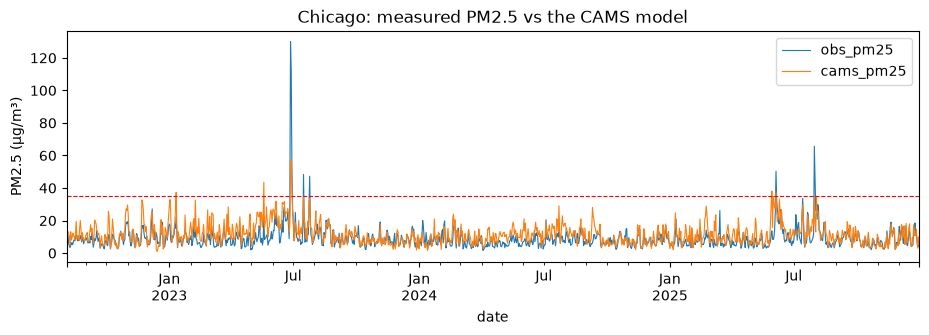

In [2]:
daily["bad"] = daily["obs_pm25"] > THRESHOLD
daily["year"] = daily["date"].str[:4]
print(daily.pivot_table(index="city", columns="year", values="bad", aggfunc="sum", margins=True))

chicago = daily[daily["city"] == "Chicago"].set_index(pd.to_datetime(daily.loc[daily["city"] == "Chicago", "date"]))
ax = chicago[["obs_pm25", "cams_pm25"]].plot(figsize=(11, 3), lw=0.8, title="Chicago: measured PM2.5 vs the CAMS model")
ax.axhline(THRESHOLD, color="red", ls="--", lw=0.8)
ax.set_ylabel("PM2.5 (µg/m³)");

## 3. Split by time

We train on earlier dates and test on later ones, and never shuffle days together:
**train = Aug 2022 to Dec 2024, test = all of 2025.** The test year has its own smoke season
(June and late July / early August 2025). We don't use it for any choice; we score it once, in section 7.

In [3]:
print(daily.groupby("split").agg(first_day=("date", "min"), last_day=("date", "max"),
                                 city_days=("date", "size"), bad_days=("bad", "sum")))

        first_day    last_day  city_days  bad_days
split                                             
test   2025-01-01  2025-12-31       2190        35
train  2022-08-04  2024-12-31       5286        38


## 4. What we know the evening before

The athletic director decides the evening before. So each row is one **target day** (tomorrow), and the
inputs are only things known by then:

- **this city's readings:** today, yesterday and the day before (`obs_1`, `obs_2`, `obs_3`), and today's change
- **the region:** today's highest and average reading across all six cities. Smoke drifts across the Midwest, so
  a smoky Minneapolis today can mean a smoky Chicago tomorrow.
- **smoke maps:** today's NOAA plume over this city, and the heaviest plume over any of the six cities
- **the CAMS model today**, and how far off it was today compared with the monitors (`cams_miss_today`)
- **tomorrow's weather forecast:** rain washes smoke out, wind direction says where air comes from
- the day of the year, and which city it is

In [4]:
def add_features(df):
    df = df.sort_values(["city", "date"]).copy()
    by_city = df.groupby("city")
    for k in (1, 2, 3):
        df[f"obs_{k}"] = by_city["obs_pm25"].shift(k)  # shift(1) moves today's value onto tomorrow's row
    df["change_today"] = df["obs_1"] - df["obs_2"]
    df["cams_today"] = by_city["cams_pm25"].shift(1)
    df["cams_max_today"] = by_city["cams_pm25_max"].shift(1)
    df["cams_miss_today"] = df["obs_1"] - df["cams_today"]
    df["smoke_today"] = by_city["smoke"].shift(1)
    region = df.groupby("date").agg(region_max_today=("obs_pm25", "max"), region_mean_today=("obs_pm25", "mean"),
                                    region_smoke_today=("smoke", "max")).shift(1)  # shift(1): today's, not tomorrow's
    df = df.join(region, on="date")
    df["day_of_year"] = pd.to_datetime(df["date"]).dt.day_of_year
    df["city_id"] = df["city"].astype("category").cat.codes
    return df.dropna(subset=["obs_3"]).reset_index(drop=True)  # the first three days have no history


FEATURES = ["obs_1", "obs_2", "obs_3", "change_today", "region_max_today", "region_mean_today",
            "smoke_today", "region_smoke_today", "cams_today", "cams_max_today", "cams_miss_today",
            "temp_c", "humidity", "precip_mm", "wind_kmh", "wind_u", "wind_v", "day_of_year", "city_id"]
WEATHER = ["temp_c", "humidity", "precip_mm", "wind_kmh", "wind_u", "wind_v"]

df = add_features(daily)
train = df[df["split"] == "train"].copy()
print(f"training rows: {len(train):,}   features: {len(FEATURES)}")

training rows: 5,268   features: 19


## 5. Baselines: four forecasts our model has to beat

1. **Persistence:** tomorrow will be the same as today.
2. **Climatology:** tomorrow will be the average for this city and month (from the training years only).
3. **NOAA's official forecast (NAQFC):** what the US National Air Quality Forecast Capability predicted for the
   target day's average PM2.5, in its 12Z run the day before (6 am Central). This is the professional forecast
   an athletic director could really have looked up. We take the grid cell nearest the city centre. Its
   24-hour window runs 10 pm to 10 pm Central, 22 of the 24 hours of EPA's day. NOAA upgraded the model in May 2024.
4. **Raw CAMS:** the CAMS model's number for the target day. Open-Meteo does not keep what CAMS predicted
   *a day ahead*: we checked, and its "previous day" values are empty for 2022 to 2025. The CAMS history it
   serves is stitched from short-range runs that already "see" the smoke. So this baseline is **stronger than
   any real day-ahead forecast**, and we don't let our model use it. We keep it as an optimistic upper bar.

In [5]:
df["month"] = df["date"].str[5:7].astype(int)
df = df.join(train.assign(month=train["date"].str[5:7].astype(int))
             .groupby(["city", "month"])["obs_pm25"].mean().rename("pred_climatology"), on=["city", "month"])
df["pred_persistence"] = df["obs_1"]
df["pred_noaa"] = df["naqfc_pm25"]
df["pred_cams"] = df["cams_pm25"]
train = df[df["split"] == "train"].copy()

## 6. Choose the model and the warning rule, using the training years only

**Checking choices without touching 2025.** We hide one training year at a time (Aug-Dec 2022, 2023, 2024),
train on the other two, and predict the hidden one. Each year is kept whole, so days are never mixed.
Every training day then gets a prediction from a model that never saw it.

**Two models, averaged:**
- a **Ridge regression** (a weighted sum of the inputs). It can go higher than anything it has seen,
  which matters when smoke is worse than the training years.
- a **gradient-boosted tree model** that predicts **the change from today**, not the level. Trees can't predict
  values outside the range they were trained on, but a change added to today's reading can be large.

In [6]:
def make_ridge():
    # StandardScaler puts every input on the same scale, so Ridge's penalty treats them equally
    return make_pipeline(StandardScaler(), Ridge(alpha=1.0))


def make_trees(loss="absolute_error"):
    return HistGradientBoostingRegressor(loss=loss, max_iter=300, learning_rate=0.05, random_state=0,
                                         categorical_features=[FEATURES.index("city_id")])


def fit(rows):
    ridge = make_ridge().fit(rows[FEATURES].drop(columns="city_id"), rows["obs_pm25"])
    trees = make_trees().fit(rows[FEATURES], rows["obs_pm25"] - rows["obs_1"])
    return ridge, trees


def predict(models, rows):
    ridge, trees = models
    from_ridge = ridge.predict(rows[FEATURES].drop(columns="city_id")).clip(min=0)
    from_trees = rows["obs_1"] + trees.predict(rows[FEATURES])
    return (from_ridge + from_trees) / 2


train["block"] = np.where(train["date"] < "2023-01-01", "2022 (Aug-Dec)", train["date"].str[:4])
train["pred_model"] = np.nan
train["pred_trees_level"] = np.nan  # the version we tried first and dropped (see below)
for block in train["block"].unique():
    seen, hidden = train[train["block"] != block], train[train["block"] == block]
    train.loc[hidden.index, "pred_model"] = predict(fit(seen), hidden)
    plain = make_trees("squared_error").fit(seen[FEATURES], seen["obs_pm25"])
    train.loc[hidden.index, "pred_trees_level"] = plain.predict(hidden[FEATURES])

print("bad days in each training block:", train.groupby("block")["bad"].sum().to_dict())

bad days in each training block: {'2022 (Aug-Dec)': 0, '2023': 36, '2024': 2}


**The warning rule.** A forecast becomes a warning ("move practice indoors") when it goes above a cut-off.
The cut-off doesn't have to be 35: a forecast that tends to come in low should warn earlier.

We decided before looking at any results that **one missed bad day costs as much as 5 false alarms**.
Sending kids to run in smoke is much worse than an unneeded indoor practice, but if SmokeCheck cries wolf every
week, the athletic director stops listening. For **every** forecast, baselines included, we pick the cut-off
with the lowest cost on the training years, so the comparison is fair.

In [7]:
COST_OF_A_MISS = 5


def warning_counts(rows, col, warn_at):
    real, warned = rows["obs_pm25"] > THRESHOLD, rows[col] > warn_at
    return {"caught": int((real & warned).sum()), "missed": int((real & ~warned).sum()),
            "false_alarms": int((~real & warned).sum())}


def best_cut_off(rows, col):
    rows = rows[rows[col].notna()]  # NOAA has no forecast for 3 run days in 2022-23
    def cost(t):
        c = warning_counts(rows, col, t)
        return COST_OF_A_MISS * c["missed"] + c["false_alarms"]
    return min(np.arange(10, 45.5, 0.5), key=cost)


FORECASTS = ["pred_persistence", "pred_climatology", "pred_noaa", "pred_cams", "pred_model"]
warn_at = {col: float(best_cut_off(train, col)) for col in FORECASTS + ["pred_trees_level"]}


def score(rows, col):
    """Average error, plus warnings using that forecast's own cut-off."""
    rows = rows[rows[col].notna()]
    out = {"mae": round(float((rows[col] - rows["obs_pm25"]).abs().mean()), 2), "days": int(len(rows)),
           "bad_days": int((rows["obs_pm25"] > THRESHOLD).sum()), "warn_at": warn_at[col]}
    out.update(warning_counts(rows, col, warn_at[col]))
    out["recall"] = round(out["caught"] / out["bad_days"], 3) if out["bad_days"] else None
    return out


print("Training years, each predicted by a model that didn't see that year")
print(pd.DataFrame({col: score(train, col) for col in FORECASTS + ["pred_trees_level"]}).T)

Training years, each predicted by a model that didn't see that year
                   mae    days  bad_days  warn_at  caught  missed  \
pred_persistence  3.23  5268.0      38.0     37.0    17.0    21.0   
pred_climatology  3.89  5268.0      38.0     19.5     0.0    38.0   
pred_noaa         3.38  5250.0      38.0     45.0     7.0    31.0   
pred_cams         3.79  5268.0      38.0     29.5    28.0    10.0   
pred_model        2.49  5268.0      38.0     24.0    21.0    17.0   
pred_trees_level  2.74  5268.0      38.0     42.5     1.0    37.0   

                  false_alarms  recall  
pred_persistence          18.0   0.447  
pred_climatology           0.0   0.000  
pred_noaa                 27.0   0.184  
pred_cams                 45.0   0.737  
pred_model                26.0   0.553  
pred_trees_level           3.0   0.026  


**What we tried and dropped:** one tree model predicting the PM2.5 level directly (`pred_trees_level`).
Its average error was good, but it caught almost none of the bad days. When 2023 is hidden, the other
training years have only 2 bad days and a highest reading of 48, and a tree model can't predict above what
it has seen. Predicting the change from today, and averaging with Ridge, fixed most of that.

**Also tried and dropped: upwind smoke.** Smoke that reaches the Midwest often comes from Canada, so we added
the heaviest NOAA-mapped smoke 300, 600 and 900 km upwind of each city today (`fetch_upwind_smoke.py`). Upwind
smoke came before 16 of the 21 training arrival days, against 17% of ordinary days, so the signal is real. But on
the training-year check it changed nothing (average error 2.49 with or without it), so we left it out. Our guess:
when 2023 is hidden, the other training years have only 2 bad days, so the model can't learn what upwind smoke means.
We also noticed that leaving out just six rows moved the training-year warning count by a few days. With 38 bad
days, mostly from one event, warning numbers are noisy; the average error is much steadier.

**Also tried and dropped: more years of history (2018 to mid-2022).** To give the model more smoke seasons,
`fetch_early.py` adds the 4.6 years before our data starts (`data/daily_early.csv`: EPA readings, the same
Open-Meteo weather archive, NOAA smoke maps). CAMS doesn't exist on Open-Meteo before August 2022, so the longer
model leaves out the three CAMS inputs. The extra years have few bad days: 7, and only 3 of them are smoke
(Minneapolis, July 29-31, 2021). Three are probably Fourth of July fireworks in 2020 (July 4-5, no smoke on the
NOAA maps) and one is a December day in Detroit; the September 2020 western smoke never pushed a city's daily
average above 35. Before running the comparison we wrote down the rule: adopt the longer model only if, on the same 2022-2024 days, its average error is lower
**and** its warning cost (5 × missed + false alarms) isn't higher. `compare_seasons.py` hides one year at a time:

| Training-year check, 2022-08-07 to 2024 (38 bad days) | average error | warn above | caught | missed | false alarms | cost | arrival days caught |
|---|---|---|---|---|---|---|---|
| current model | 2.49 | 24 | 21 | 17 | 26 | 111 | 4 of 21 |
| current model without CAMS | 2.48 | 29.5 | 18 | 20 | 12 | 112 | 1 of 21 |
| 2018-2024, without CAMS | 2.38 | 27.5 | 18 | 20 | 15 | 115 | 1 of 21 |
| 2018-2024, without CAMS, plus upwind smoke | 2.39 | 30 | 17 | 21 | 11 | 116 | 1 of 21 |

More years lowered the average error in every hidden year (by 0.06 to 0.15), but the warning cost went up a
little, so by our rule we kept the current model and never scored the longer one on 2025. What we learned:
dropping CAMS alone took arrival-day catches from 4 to 1 of 21 (each at its own cut-off). With numbers this
small that's a hint that CAMS helps on arrival days, not proof. Upwind smoke still didn't help, but the extra
years add only 3 smoke bad days, so this was a weak test of our guess about it. A cost gap of 4 is less than one missed day, so the call is close. A version that
keeps CAMS where it exists might get both; we didn't try it, because we had decided not to add variants after
seeing these results.

## 7. The test: 2025, scored once

We train on all the training years and predict every day of 2025.

**Weather honesty.** The weather in our main table is almost the real weather (Open-Meteo stitches it from
the first hours of each forecast). The evening before, the athletic director only has a forecast. For 2025,
Open-Meteo keeps the forecast made one day earlier, so **the test uses that day-ahead forecast**. (We had to
train on the stitched weather, because day-ahead forecasts don't exist for 2022-2023.)

In [8]:
models = fit(train)
test = df[df["split"] == "test"].copy()
test["pred_model_with_stitched_weather"] = predict(models, test)  # for comparison only
test = test.drop(columns=WEATHER).merge(dayahead_wx, on=["city", "date"])
test["pred_model"] = predict(models, test)
warn_at["pred_model_with_stitched_weather"] = warn_at["pred_model"]

results = pd.DataFrame({col: score(test, col) for col in FORECASTS + ["pred_model_with_stitched_weather"]}).T
print("Test year 2025, all six cities")
results

Test year 2025, all six cities


,mae,days,bad_days,warn_at,caught,missed,false_alarms,recall
pred_persistence,3.40,2190.0,35.0,37.0,12.0,23.0,19.0,0.343
pred_climatology,4.33,2190.0,35.0,19.5,0.0,35.0,0.0,0.000
pred_noaa,3.20,2190.0,35.0,45.0,6.0,29.0,1.0,0.171
pred_cams,3.72,2190.0,35.0,29.5,18.0,17.0,21.0,0.514
pred_model,2.59,2190.0,35.0,24.0,18.0,17.0,22.0,0.514
pred_model_with_stitched_weather,2.58,2190.0,35.0,24.0,18.0,17.0,23.0,0.514


## 8. Where it works and where it fails

**Arrival days vs continuing days.** A bad day is an *arrival* when the day before was fine (35 or below),
and *continuing* when the day before was already bad. Persistence can never warn on an arrival day, because
it always repeats today. Arrival days are where a forecast proves it's worth having.

In [9]:
test["is_smoke_day"] = test["smoke"] >= 2  # NOAA drew a medium or heavy plume over the city on the target day
bad = test[test["obs_pm25"] > THRESHOLD].copy()
bad["kind"] = np.where(bad["obs_1"] > THRESHOLD, "continuing", "arrival")
for col in ["pred_persistence", "pred_noaa", "pred_cams", "pred_model"]:
    bad[col.removeprefix("pred_") + "_warned"] = bad[col] > warn_at[col]
print(bad.groupby("kind")[["persistence_warned", "noaa_warned", "cams_warned", "model_warned"]].agg(["sum", "size"]))

           persistence_warned      noaa_warned      cams_warned       \
                          sum size         sum size         sum size   
kind                                                                   
arrival                     0   21           4   21          11   21   
continuing                 12   14           2   14           7   14   

           model_warned       
                    sum size  
kind                          
arrival               6   21  
continuing           12   14  


In [10]:
print("Every bad day in 2025:")
print(bad[["date", "city", "kind", "obs_pm25", "obs_1", "pred_persistence", "pred_noaa", "pred_cams", "pred_model", "smoke"]]
      .round(1).sort_values("date").to_string(index=False))

Every bad day in 2025:
      date        city       kind  obs_pm25  obs_1  pred_persistence  pred_noaa  pred_cams  pred_model  smoke
2025-03-15   St. Louis    arrival      56.3   16.0              16.0        9.0        7.6         8.8      0
2025-06-03 Minneapolis    arrival      80.0   12.3              12.3       46.2       33.2         7.9      1
2025-06-04     Madison    arrival      49.4   15.0              15.0       58.5       23.0        17.9      1
2025-06-04   Milwaukee    arrival      43.6   10.7              10.7       45.5       28.1        15.7      1
2025-06-05     Chicago    arrival      50.3   25.4              25.4       30.2       37.7        20.1      1
2025-06-05     Detroit    arrival      43.8   23.9              23.9       18.5       34.6        19.8      2
2025-06-05   Milwaukee continuing      39.4   43.6              43.6       47.0       32.1        37.7      1
2025-06-06     Detroit continuing      50.4   43.8              43.8       38.8       36.2       

In [11]:
false_alarms = test[(test["obs_pm25"] <= THRESHOLD) & (test["pred_model"] > warn_at["pred_model"])]
print(f"Model false alarms in 2025: {len(false_alarms)}")
print(false_alarms[["date", "city", "obs_pm25", "obs_1", "pred_model", "smoke"]].round(1).to_string(index=False))

Model false alarms in 2025: 22
      date        city  obs_pm25  obs_1  pred_model  smoke
2025-06-06     Chicago      32.8   50.3        33.5      2
2025-07-14     Chicago      33.6   23.6        27.6      1
2025-07-15     Chicago      19.5   33.6        24.9      2
2025-08-02     Chicago      26.2   45.5        27.2      2
2025-08-04     Chicago      20.8   31.9        24.2      1
2025-08-06     Chicago      27.9   29.8        25.0      2
2025-06-07     Detroit      22.7   50.4        30.1      1
2025-06-09     Detroit      22.3   36.8        25.9      1
2025-08-01     Detroit      14.2   45.9        38.9      1
2025-08-05     Detroit      32.8   53.8        32.4      2
2025-06-05     Madison      30.4   49.4        37.9      1
2025-07-14     Madison      16.5   37.7        31.1      1
2025-07-22     Madison      15.7   30.1        25.3      1
2025-06-06   Milwaukee      25.9   39.4        24.4      2
2025-07-14   Milwaukee      26.0   44.5        39.0      1
2025-08-06   Milwaukee   

**By city, and smoke days vs clean days** (average error, µg/m³)

In [12]:
by_city = test.groupby("city").apply(lambda g: pd.Series({c.removeprefix("pred_"): score(g, c)["mae"] for c in FORECASTS}),
                                     include_groups=False)
by_smoke = test.groupby("is_smoke_day").apply(lambda g: pd.Series({c.removeprefix("pred_"): score(g, c)["mae"] for c in FORECASTS}),
                                              include_groups=False)
print(by_city, "\n")
print(by_smoke.rename(index={False: "clean (no medium/heavy plume)", True: "smoke day"}))

             persistence  climatology  noaa  cams  model
city                                                    
Chicago             3.28         4.22  3.07  3.95   2.41
Detroit             3.60         4.66  3.19  3.27   2.47
Madison             3.30         4.26  3.06  3.35   2.65
Milwaukee           3.47         4.68  3.25  3.27   2.67
Minneapolis         3.95         4.88  3.97  4.58   3.03
St. Louis           2.81         3.27  2.67  3.86   2.31 

                               persistence  climatology   noaa   cams  model
is_smoke_day                                                                
clean (no medium/heavy plume)         3.02         3.82   2.75   3.31   2.24
smoke day                             9.86        12.99  10.82  10.53   8.63


## 9. The demo day: Thursday, July 31, 2025 in Chicago

On July 30, Chicago measured 12 µg/m³. On the 31st it measured 66.

In [13]:
week = test[(test["city"] == "Chicago") & test["date"].between("2025-07-29", "2025-08-03")]
print({c: warn_at[c] for c in ["pred_persistence", "pred_noaa", "pred_cams", "pred_model"]}, "<- warn above these")
print(week[["date", "obs_pm25", "pred_persistence", "pred_noaa", "pred_cams", "pred_model", "region_max_today", "smoke_today"]]
      .round(1).to_string(index=False))

{'pred_persistence': 37.0, 'pred_noaa': 45.0, 'pred_cams': 29.5, 'pred_model': 24.0} <- warn above these
      date  obs_pm25  pred_persistence  pred_noaa  pred_cams  pred_model  region_max_today  smoke_today
2025-07-29       9.4               8.2        8.8       19.6         8.3               8.5          1.0
2025-07-30      12.4               9.4        9.3       17.1         7.7               9.9          2.0
2025-07-31      65.6              12.4       13.7       34.3        13.9              50.6          2.0
2025-08-01      45.5              65.6        8.7       19.1        54.8              83.7          2.0
2025-08-02      26.2              45.5       11.4       13.0        27.2              75.3          2.0
2025-08-03      31.9              26.2       25.2       34.2        18.6              47.4          2.0


## 10. Limits we know about

- **One smoke event dominates training.** 36 of the 38 bad training days are from 2023, mostly one June event.
  Going back to 2018 doesn't fix this: those years add only 3 smoke bad days (section 6).
- **"Today" isn't fully known in the evening.** We use today's full-day average; at 6 pm the last hours are missing.
- **Smoke maps use UTC days**, 5-6 hours ahead of Chicago, and analysts may finish them late in the day.
  Light plumes don't count as smoke days, and 12 of the 35 bad test days had only a light plume or none.
- **Weather mismatch:** trained on near-real weather, tested on day-ahead forecasts (section 7).
- **CAMS is a 45 km model estimate**, and its archive isn't a real day-ahead forecast (section 5).
- Six cities, 2.4 years of training data. Monitors are averaged over each metro area, so one neighbourhood can be worse.

## 11. Save the forecasts for the app

In [14]:
metrics = {
    "threshold": THRESHOLD,
    "cost_of_a_miss": COST_OF_A_MISS,
    "warn_at": {c: warn_at[c] for c in FORECASTS},
    "test_period": [test["date"].min(), test["date"].max()],
    "overall": {c: score(test, c) for c in FORECASTS},
    "by_city": {city: {c: score(g, c) for c in FORECASTS} for city, g in test.groupby("city")},
    "by_smoke": {("smoke_day" if k else "clean_day"): {c: score(g, c) for c in FORECASTS} for k, g in test.groupby("is_smoke_day")},
    "training_years_out_of_fold": {c: score(train, c) for c in FORECASTS},
}
train["is_smoke_day"] = train["smoke"] >= 2
cols = ["date", "city", "lat", "lon", "obs_pm25"] + FORECASTS + ["is_smoke_day", "split"]
os.makedirs("data", exist_ok=True)
pd.concat([train[cols], test[cols]]).sort_values(["city", "date"]).round(2).to_csv("data/predictions.csv", index=False)
with open("data/metrics.json", "w") as f:
    json.dump(metrics, f, indent=1)
print("saved data/predictions.csv and data/metrics.json")

saved data/predictions.csv and data/metrics.json


## Sources

- **EPA AirData** daily PM2.5 (parameter 88101), https://aqs.epa.gov/aqsweb/airdata/download_files.html
- **CAMS global atmospheric composition forecasts** (Copernicus Atmosphere Monitoring Service) via the
  **Open-Meteo Air Quality API**, https://open-meteo.com/en/docs/air-quality-api
- **Open-Meteo** Historical Forecast API and Previous Runs API (weather), https://open-meteo.com
- **NOAA National Air Quality Forecast Capability (NAQFC)** PM2.5 forecasts, NOAA Open Data on AWS,
  https://registry.opendata.aws/noaa-nws-naqfc-pds/ (bias-corrected 24-hour average, CONUS 5 km grid)
- **NOAA Hazard Mapping System** smoke polygons, https://www.ospo.noaa.gov/products/land/hms.html
- Libraries: pandas, NumPy, scikit-learn, matplotlib, pyshp, eccodes (reads NOAA's GRIB files), jupytext
- AI tools: Claude (Anthropic), through Claude Code. It wrote most of the code (data scripts, this notebook, the app)
  and ran the experiments, researched which datasets and forecast archives to use, and drafted the write-up.
  We chose the track and project and picked which ideas to try from the options it proposed.